В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-19,81853.539062,2404.815186,104.926231,1.302713,0.217995,1.153126,12.043903,0.177571,605.426392
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082


In [4]:
sequence_length = 365 * 5

In [5]:
token_num = 5

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['BTC', 'XMR', 'XRP', 'ETH', 'ADA']

In [6]:
# strategy={"extra_buy_amount": 500}
strategy={}

06:03:42 - cmdstanpy - INFO - Chain [1] start processing
06:03:42 - cmdstanpy - INFO - Chain [1] done processing


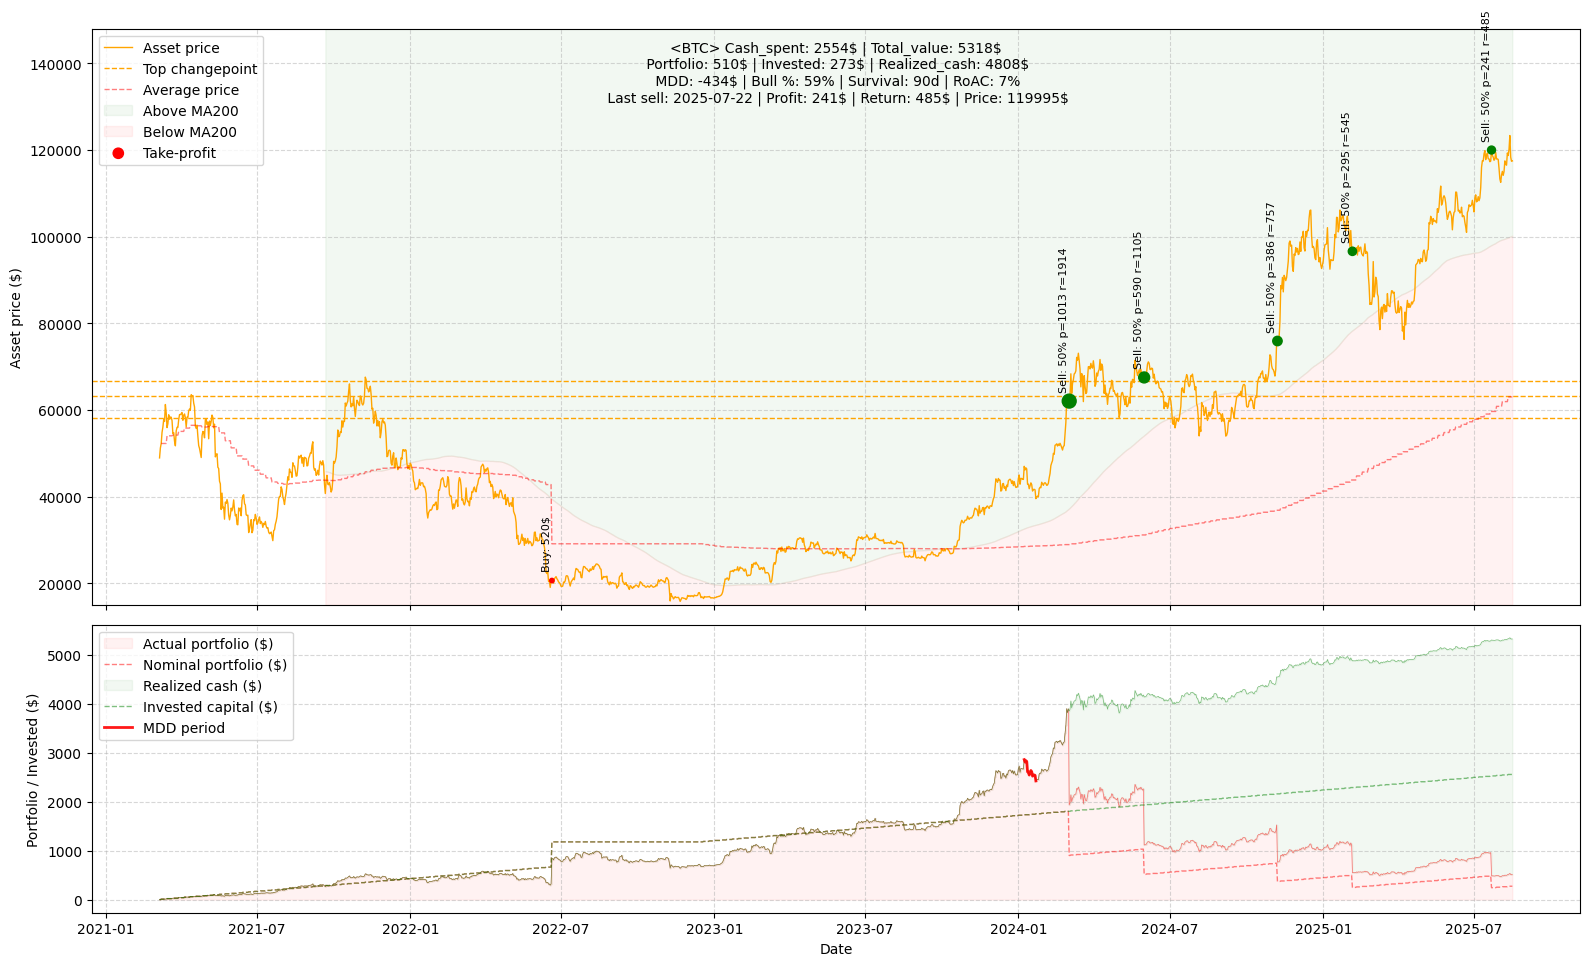

06:03:42 - cmdstanpy - INFO - Chain [1] start processing
06:03:43 - cmdstanpy - INFO - Chain [1] done processing


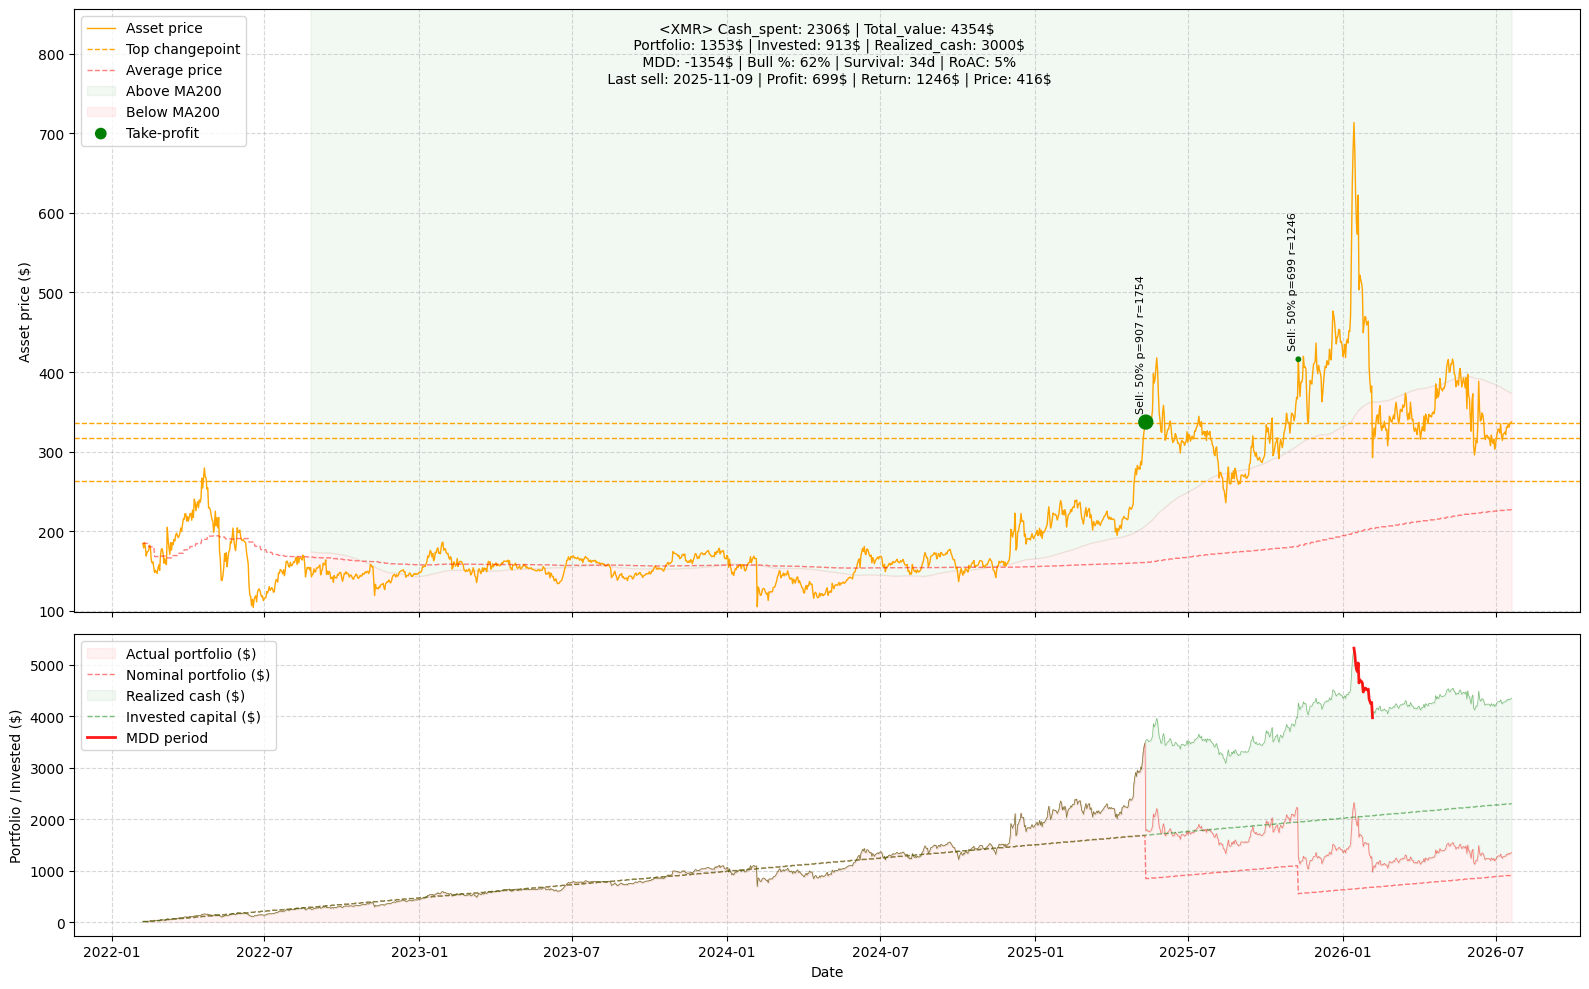

06:03:43 - cmdstanpy - INFO - Chain [1] start processing
06:03:43 - cmdstanpy - INFO - Chain [1] done processing


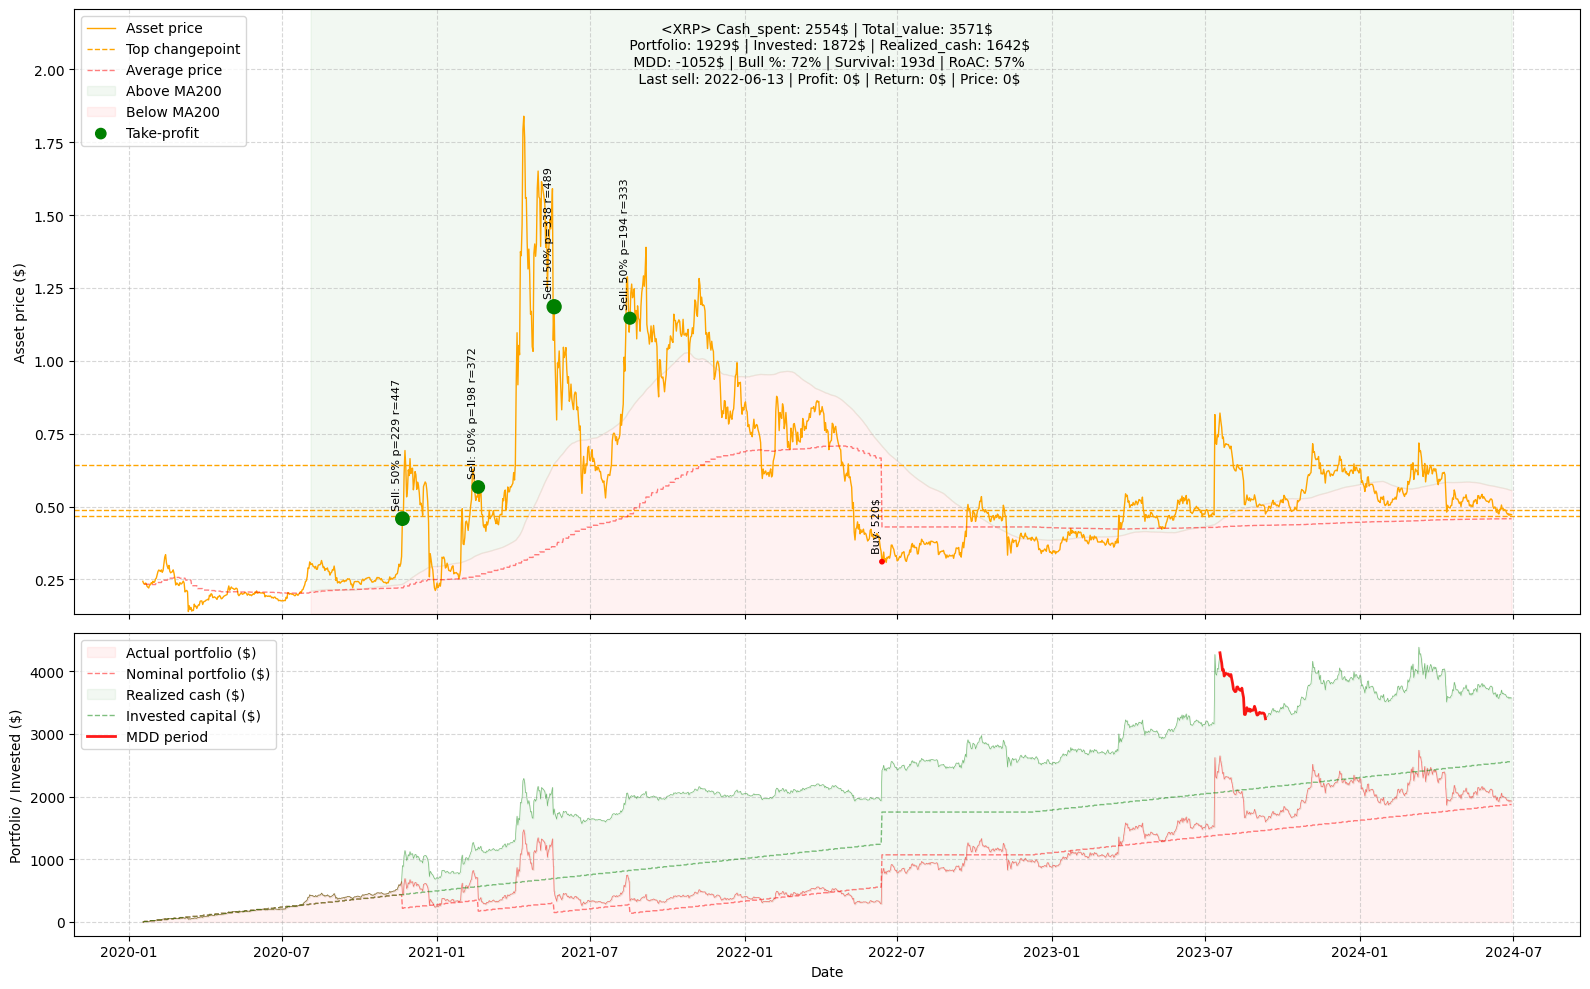

06:03:44 - cmdstanpy - INFO - Chain [1] start processing
06:03:44 - cmdstanpy - INFO - Chain [1] done processing


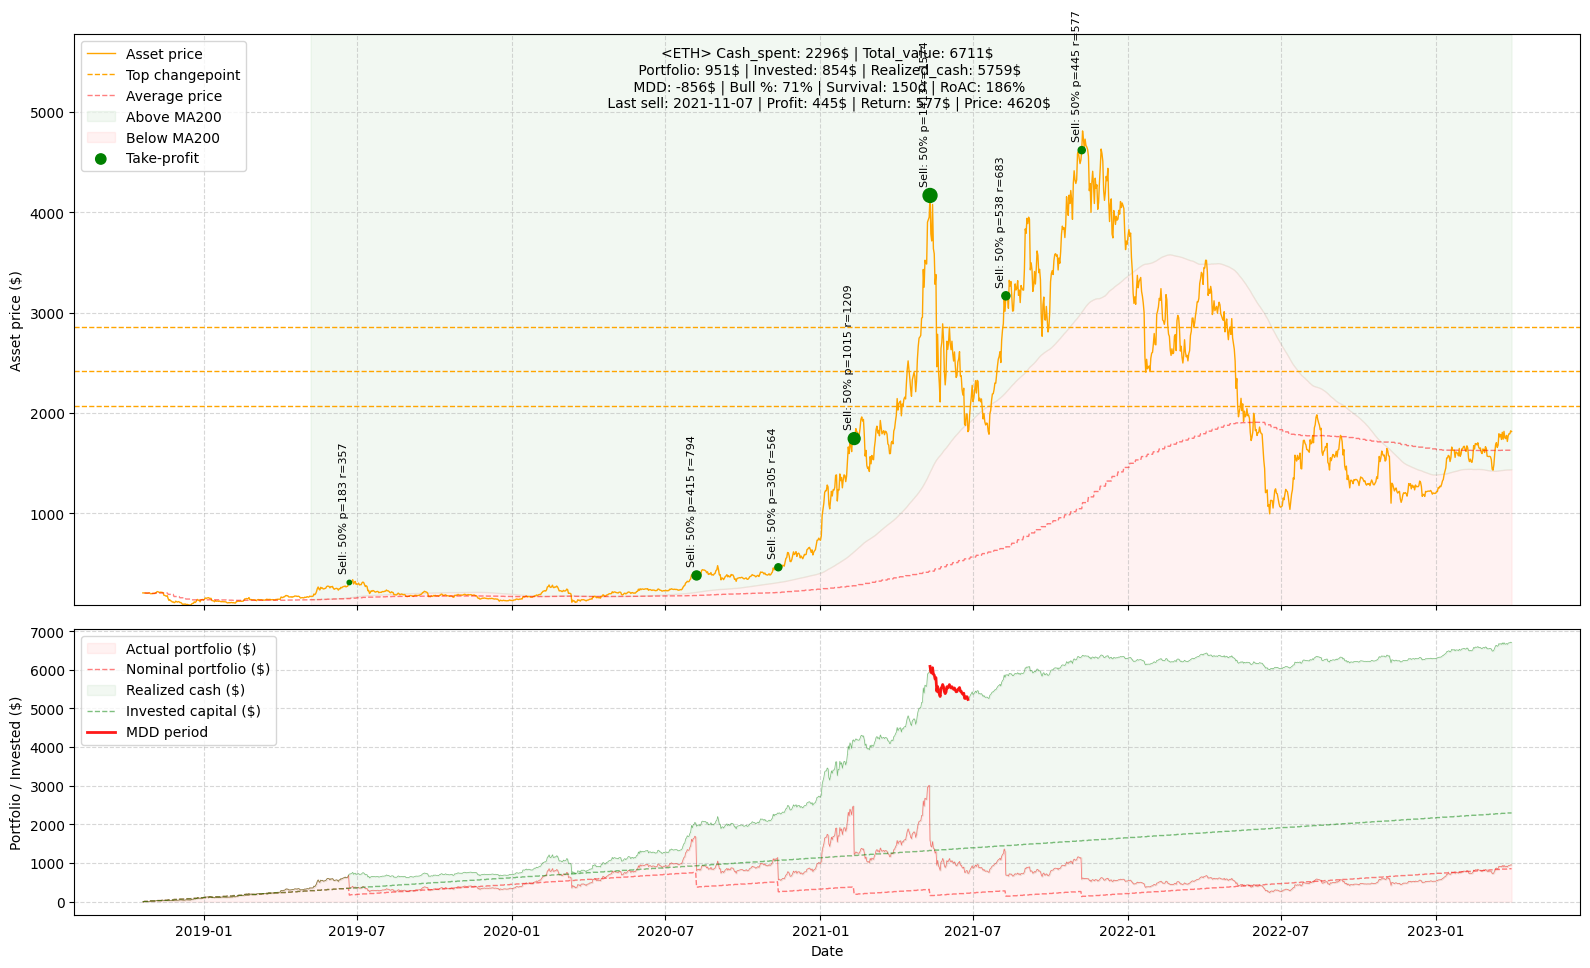

06:03:44 - cmdstanpy - INFO - Chain [1] start processing
06:03:45 - cmdstanpy - INFO - Chain [1] done processing


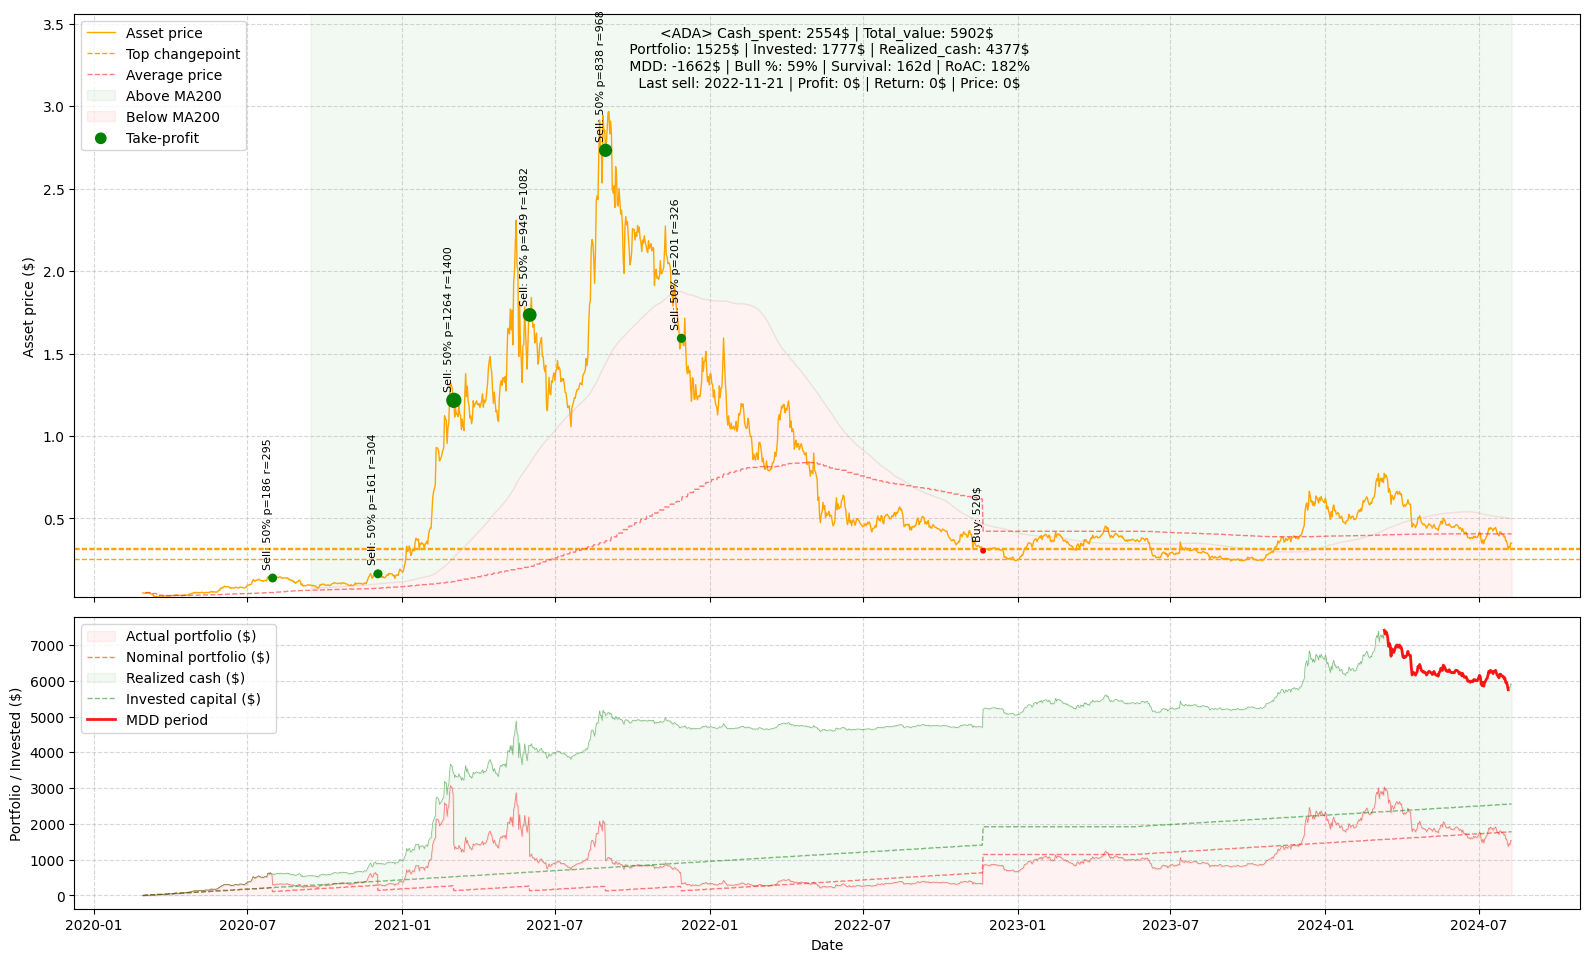

Total invested: $12264.00
Total return: $19586.00
Total value: $25856.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2020-02-28,0.048616,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-02-29,0.047541,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-03-01,0.045932,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2020-03-02,0.048953,202.234795,9.900000,9.9,0.0,0.0,0.000000,,9.900000,0.048953,9.900000
2020-03-03,0.048761,202.234795,9.900000,9.9,0.0,0.0,0.000000,,9.861171,0.048953,9.861171
...,...,...,...,...,...,...,...,...,...,...,...
2024-08-05,0.313155,4375.498221,1777.978125,2554.2,0.0,0.0,4377.664818,,1370.209125,0.406349,5747.873943
2024-08-06,0.330782,4375.498221,1777.978125,2554.2,0.0,0.0,4377.664818,,1447.336036,0.406349,5825.000854
2024-08-07,0.323698,4375.498221,1777.978125,2554.2,0.0,0.0,4377.664818,,1416.340084,0.406349,5794.004902


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1622)

In [10]:
metrics

{'Target': 'ADA',
 'Cash_spent': 2554,
 'Realized_cash': 4377,
 'Portfolio': 1525,
 'Invested': 1777,
 'Total_value': 5902,
 'Bull_history': 59,
 'Avg_price': np.float64(0.4063487254147928),
 'Num_take_profits': 6,
 'MDD': -1662,
 'MA200_survival_days': 162.0,
 'RoAC': 182}